(sec-3-1)=
# 3.1 What Is a System?

An ECG passes through several steps before we see it on a screen: amplification, sampling, and often some filtering. Each step takes a signal as input and produces a signal as output. In signal processing, I call any such rule a *system*.

We will start with familiar operations, such as multiplying a recording by a constant or averaging neighboring samples. Then we will connect those operations to mathematical notation and Python functions. The main question throughout is: what did this operation change, and what information did it keep?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
from matplotlib.patches import FancyBboxPatch, Circle

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-3-1-1)=
## 3.1.1 Signals In, Signals Out

A system is a rule that assigns an output signal to every input signal in some class of allowed inputs. We write this with **operator notation**,

(eq-3-1)=
\begin{equation*}
y = \mathcal{T}\{x\}, \tag{3.1}
\end{equation*}

Here $x$ is the whole input signal, $y$ is the whole output, and $\mathcal{T}$ names the processing rule. For a gain of two, the rule is $\mathcal{T}\{x\}=2x$: an input sample of $0.3$ mV becomes $0.6$ mV. The braces mean ‘apply this rule to the signal’; they do not mean multiplication by a number called $\mathcal{T}$.

which reads "$y$ is the response of the system $\mathcal{T}$ to the input $x$". The braces matter. A system acts on the *entire* input signal and returns an entire output signal, not one number at a time. You will often see the shorthand $y(t) = \mathcal{T}\{x(t)\}$, and we will use it too when nothing can go wrong, but it hides an important fact: the output at time $t$ may depend on the input at many other times. A moving average, for example, produces $y$ at 10.000 s from input samples taken between 9.983 s and 10.000 s. The careful reading of $y(t) = \mathcal{T}\{x\}(t)$ is "apply $\mathcal{T}$ to the whole function $x$, then evaluate the resulting function at $t$". This distinction becomes essential in Section 4.3, where we shift signals in time and ask whether the system notices.

Systems come in two flavors that mirror the two kinds of signals. A **continuous-time system** maps a function $x(t)$ to a function $y(t)$; the RC network at the input of an ECG amplifier and the cardiovascular system itself are examples. A **discrete-time system** maps a sequence $x[n]$ to a sequence $y[n]$; every filter we write in Python belongs here. Some systems are hybrids: the analog-to-digital converter takes a continuous-time input and produces a discrete-time output, and the digital-to-analog converter does the reverse. Their behavior is the subject of Chapter 6. The physics of the body lives in continuous time and the processing lives in discrete time, so we need both descriptions, and most of the ideas in this chapter apply to each with only notational changes.

Systems can also have several inputs and outputs. A 12-lead electrocardiograph takes the potentials of ten electrodes and produces twelve lead signals, and the baroreflex combines pressure information from receptors in the carotid arteries and the aortic arch. In this chapter we stay with single-input, single-output systems, which already contain all of the essential ideas.

Before looking at examples, here is the input-output view in its simplest graphical form. The input is two seconds of a real ECG (MIT-BIH record 100) to which we have added a 0.15 mV, 60 Hz power-line hum, the kind of interference a poorly shielded lead picks up. The system is a six-point moving average, written down in equation [(3.3)](#eq-3-3) below. The output is a cleaner ECG, although the price is a visibly smaller R wave. I chose six points deliberately: why six points remove 60 Hz so completely at a sampling rate of 360 Hz is something we will be able to explain in Section 3.2.

In [2]:
rec = wfdb.rdrecord("../data/mitdb/100", sampto=30 * 360)
ecg = rec.p_signal[:, 0]                       # lead MLII, mV
fs = rec.fs                                    # 360 Hz
t = np.arange(ecg.size) / fs
ann = wfdb.rdann("../data/mitdb/100", "atr", sampto=30 * 360)
beat_symbols = {"N", "A", "V"}
r_peaks = np.array([s for s, sym in zip(ann.sample, ann.symbol) if sym in beat_symbols])

hum = 0.15 * np.sin(2 * np.pi * 60 * t)        # 60 Hz interference, mV
ecg_hum = ecg + hum
M = 6
ecg_clean = np.convolve(ecg_hum, np.ones(M) / M)[: ecg.size]   # equation (4.3), causal

print(f"Sampling rate: {fs} Hz, beats annotated in the first 30 s: {r_peaks.size}")
print(f"RMS of the hum before the system: {np.sqrt(np.mean(hum**2)):.3f} mV")

Sampling rate: 360 Hz, beats annotated in the first 30 s: 37
RMS of the hum before the system: 0.106 mV


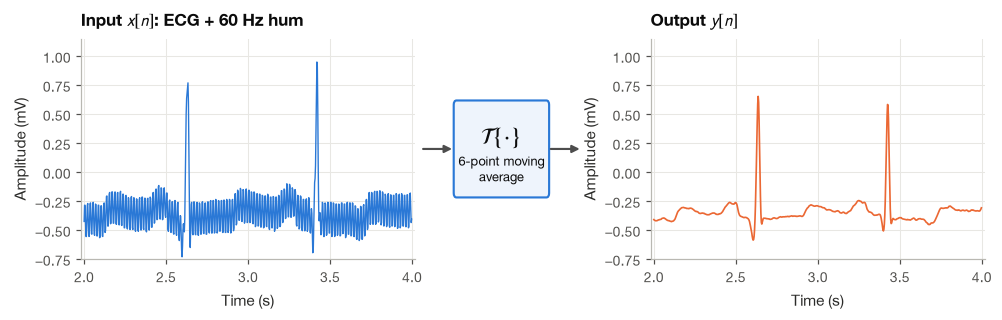

In [3]:
win = (t >= 2) & (t < 4)
fig = plt.figure(figsize=(9, 2.8))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.42, 1])
ax_in, ax_box, ax_out = (fig.add_subplot(gs[0, k]) for k in range(3))

ax_in.plot(t[win], ecg_hum[win], color=C[0], lw=0.9)
ax_in.set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="Input $x[n]$: ECG + 60 Hz hum")
ax_out.plot(t[win], ecg_clean[win], color=C[1], lw=1.1)
ax_out.set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="Output $y[n]$")
for ax in (ax_in, ax_out):
    ax.set_ylim(-0.75, 1.15)

ax_box.axis("off")
ax_box.set(xlim=(0, 1), ylim=(0, 1))
ax_box.add_patch(FancyBboxPatch((0.18, 0.3), 0.64, 0.4, boxstyle="round,pad=0.02",
                                fc="#eef4fc", ec=C[0], lw=1.4))
ax_box.text(0.5, 0.56, r"$\mathcal{T}\{\cdot\}$", ha="center", va="center", fontsize=15)
ax_box.text(0.5, 0.41, "6-point moving\naverage", ha="center", va="center", fontsize=8.5)
for x0, x1 in [(-0.08, 0.17), (0.83, 1.08)]:
    ax_box.annotate("", xy=(x1, 0.5), xytext=(x0, 0.5), annotation_clip=False,
                    arrowprops=dict(arrowstyle="-|>", color="0.3", lw=1.4))
plt.show()

(sec-3-1-2)=
## 3.1.2 A Gallery of Systems

The following systems appear again and again in ECG instrumentation and analysis, and I have picked them because each one will later illustrate a different property. For each one we write the input-output rule explicitly. In {ref}`Sections 3.2 <sec-3-2>` and 4.3 we will return to this list and classify every entry by its properties.

**Amplifier.** The simplest system multiplies its input by a constant gain $G$,

$$
y(t) = G\,x(t).
$$

The front end of an ECG recorder has a total gain of the order of 1000, so that a 1 mV R wave becomes a 1 V signal that suits the input range of the converter. A real amplifier cannot produce an output beyond its supply voltages. As long as the signal stays well inside those limits the rule $y = Gx$ is accurate; when it does not, the output is clipped, a failure we analyze in Section 3.2.5.

**Electrode.** An electrode is a transducer between two kinds of charge carriers: ions in the tissue and electrons in the wire. Two effects shape its input-output behavior. First, the metal-electrolyte interface develops a *half-cell potential*, about 0.22 V for silver/silver chloride, so the electrode adds a constant offset to the biopotential. The offsets of a pair of electrodes largely cancel in a differential measurement, but a mismatch of tens of millivolts typically remains, which is far larger than the ECG itself. Second, the interface behaves electrically like a resistor in parallel with a capacitor (the charge double layer), so its impedance is larger for slow signals than for fast ones. A crude but useful model of the electrode is therefore

$$
y(t) = x(t) + V_0 ,
$$

with $V_0$ a constant offset, followed by a frequency-dependent attenuation. This innocent-looking "add a constant" rule will turn out to be the textbook example of a system that is *not* linear in the strict sense (Example 3.2.3). {cite:t}`webster2010` gives the full electrochemistry.

**RC low-pass filter.** A resistor $R$ in series with a capacitor $C$, with the output taken across the capacitor, is the simplest analog filter and appears at the input of nearly every acquisition system. Kirchhoff's voltage law says the input voltage is split between the resistor and the capacitor, $x(t) = R\,i(t) + y(t)$. The current into a capacitor is proportional to the rate of change of its voltage, $i(t) = C\,dy/dt$. Substituting the second relation into the first,

(eq-3-2)=
\begin{equation*}
RC\,\frac{dy}{dt} + y(t) = x(t). \tag{3.2}
\end{equation*}

The system is described not by an explicit formula for $y$ but by a differential equation that $y$ must satisfy. The product $\tau = RC$ is the **time constant**: with $R = 10\ \text{k}\Omega$ and $C = 0.1\ \mu\text{F}$ we get $\tau = 1$ ms and a cutoff frequency $1/(2\pi\tau) \approx 159$ Hz. Because the capacitor stores charge, the output at time $t$ depends on the entire past of the input. We say the system has *memory*.

**Moving average.** The discrete-time workhorse for smoothing replaces each sample by the mean of the last $M$ input samples,

(eq-3-3)=
\begin{equation*}
y[n] = \frac{1}{M}\sum_{k=0}^{M-1} x[n-k]. \tag{3.3}
\end{equation*}

At $f_s = 360$ Hz, the six-point average used above spans $6/360 = 16.7$ ms, short enough to leave the 80 to 100 ms QRS complex recognizable.

**Squarer and rectifier.** The memoryless rules

$$
y[n] = x^2[n] \qquad\text{and}\qquad y[n] = |x[n]|
$$

both make the output non-negative. Squaring emphasizes large values and turns amplitude into something proportional to instantaneous power; rectification is the first step in computing the envelope of an EMG (Chapter 21).

**First difference.** The rule

(eq-3-4)=
\begin{equation*}
y[n] = x[n] - x[n-1] \tag{3.4}
\end{equation*}

measures how much the signal changed since the previous sample. Divided by $T_s$, it is the backward-difference approximation of the derivative from [Section 2.3](../ch02_math_toolkit/index.md). It responds strongly to the steep slopes of the QRS complex and weakly to the slow P and T waves, which is why every classical QRS detector contains a differentiator.

Two observations about this gallery are worth keeping in mind. The same mathematical rule can describe very different hardware: equation [(3.2)](#eq-3-2) governs an RC circuit, but as we see next, it also governs how the body eliminates a drug. And practical processing chains are built by connecting simple systems one after another, which is what we will do with the ECG in Section 3.1.6.

(sec-3-1-3)=
## 3.1.3 A Physiological System: Drug Concentration After a Dose

Pharmacokinetics describes how the body absorbs, distributes and eliminates a drug. The simplest useful model treats the body as one well-mixed compartment with an apparent volume of distribution $V$ (liters). The drug enters at a rate $r(t)$ (mg/h), and the liver and kidneys remove it at a rate proportional to the amount present. The input of this system is the dosing schedule and the output is the plasma concentration $C(t)$ (mg/L), which is what a blood test measures. (We write $C(t)$ for concentration here; the code keeps the letter `C` for the plot colors, so the concentration array is called `conc`.)

**Step 1: write the mass balance.** Let $A(t)$ be the amount of drug in the body. Its rate of change is what comes in minus what is eliminated:

$$
\frac{dA}{dt} = r(t) - k\,A(t),
$$

where $k$ (1/h) is the elimination rate constant.

**Step 2: convert amount to concentration.** Since $A(t) = V\,C(t)$ and $V$ is constant, dividing by $V$ gives

(eq-3-5)=
\begin{equation*}
\frac{dC}{dt} = -k\,C(t) + \frac{r(t)}{V}. \tag{3.5}
\end{equation*}

Compare this with the RC equation [(3.2)](#eq-3-2) divided by $RC$, $\;dy/dt = -y/(RC) + x/(RC)$. The two are the same first-order equation, with $1/k$ playing the role of the time constant $RC$. A capacitor discharging through a resistor and a drug being cleared by the kidneys are, as systems, identical.

**Step 3: solve for a single bolus.** Suppose a dose $D$ (mg) is injected quickly at $t = 0$, so that immediately afterwards $C(0) = D/V$ and $r(t) = 0$ for $t > 0$. Equation [(3.5)](#eq-3-5) becomes $dC/dt = -kC$. Separating the variables and integrating from $0$ to $t$,

(eq-3-6)=
\begin{equation*}
\begin{aligned}
\frac{dC}{C} &= -k\,dt \\[2pt]
\ln C(t) - \ln C(0) &= -k\,t \\[2pt]
C(t) &= \frac{D}{V}\,e^{-kt}, \qquad t \ge 0.
\end{aligned} \tag{3.6}
\end{equation*}

The concentration decays exponentially. The **half-life** $t_{1/2}$ is the time at which it has fallen to half its initial value. Setting $e^{-k t_{1/2}} = 1/2$ and taking logarithms gives $-k\,t_{1/2} = -\ln 2$, so

(eq-3-7)=
\begin{equation*}
t_{1/2} = \frac{\ln 2}{k}. \tag{3.7}
\end{equation*}

On a logarithmic concentration axis, equation [(3.6)](#eq-3-6) is a straight line with slope $-k$, which is how $k$ is estimated in practice from two or three blood samples.

**Step 4: repeated doses.** Most drugs are given repeatedly, say a dose $D$ every $\tau$ hours. Here we use a property that {ref}`Sections 3.2 <sec-3-2>` and 4.3 will make precise: because equation [(3.5)](#eq-3-5) is linear and its coefficients do not change with time, the response to a train of doses is the sum of time-shifted copies of the single-dose response. Just after the $(n+1)$-th dose, given at time $n\tau$, each earlier dose $m$ has been decaying for $(n - m)\tau$ hours, so

(eq-3-8)=
\begin{equation*}
\begin{aligned}
C_{\text{peak}, n} &= \frac{D}{V}\sum_{m=0}^{n} e^{-k(n-m)\tau}
 = \frac{D}{V}\sum_{i=0}^{n} \rho^{\,i}, \qquad \rho = e^{-k\tau} \\[4pt]
&= \frac{D}{V}\,\frac{1 - \rho^{\,n+1}}{1 - \rho}
\;\xrightarrow{\;n\to\infty\;}\; \frac{D}{V}\,\frac{1}{1 - \rho}.
\end{aligned} \tag{3.8}
\end{equation*}

In the second step we substituted $i = n - m$, and in the third we used the finite geometric series from [Section 2.3](../ch02_math_toolkit/index.md). Since $0 < \rho < 1$, the term $\rho^{n+1}$ vanishes as the doses accumulate, and the peak settles at a steady value. The trough just before the next dose is the peak multiplied by $\rho$.

I chose parameters of the order seen for an intravenous antibiotic in an adult: $V = 50$ L, $t_{1/2} = 6$ h, $D = 1000$ mg every $\tau = 12$ h. Then $D/V = 20$ mg/L and $\rho = e^{-(\ln 2/6)\cdot 12} = 2^{-2} = 1/4$. The steady-state peak is $20/(3/4) \approx 26.7$ mg/L and the steady-state trough is $26.7/4 \approx 6.7$ mg/L. The factor $1/(1 - \rho) = 4/3$ is called the *accumulation factor*.

To simulate the model we turn it into a discrete-time system. Sample time every $\Delta t = 0.1$ h. Between two samples with no dose, equation [(3.6)](#eq-3-6) says the concentration is multiplied by $a = e^{-k\Delta t}$; a dose given at sample $n$ adds $D/V$. Writing $d[n]$ for the dose (mg) given at sample $n$,

(eq-3-9)=
\begin{equation*}
C[n] = a\,C[n-1] + \frac{d[n]}{V}. \tag{3.9}
\end{equation*}

This is a *recursive* discrete-time system: the new output is computed from the previous output. It is exact at the sample times, not an approximation, and we will meet its general form again in [Section 5.5](../ch05_convolution/index.md).

In [4]:
def one_compartment(dose_mg, dt_h, V_L, k_per_h):
    """Plasma concentration (mg/L) of a one-compartment model driven by boluses, equation (4.9)."""
    a = np.exp(-k_per_h * dt_h)
    conc = np.zeros(dose_mg.size)
    previous = 0.0
    for n, d in enumerate(dose_mg):
        conc[n] = a * previous + d / V_L
        previous = conc[n]
    return conc


V, t_half, D, tau = 50.0, 6.0, 1000.0, 12.0     # L, h, mg, h
k = np.log(2) / t_half                           # equation (4.7)
dt = 0.1                                         # h
t_pk = np.arange(0, 96, dt)
dose_idx = np.round(np.arange(0, 96, tau) / dt).astype(int)   # samples at 0, 12, ..., 84 h

single = np.zeros(t_pk.size)
single[0] = D
repeated = np.zeros(t_pk.size)
repeated[dose_idx] = D

conc_single = one_compartment(single, dt, V, k)
conc_rep = one_compartment(repeated, dt, V, k)

rho = np.exp(-k * tau)
peak_ss = D / V / (1 - rho)                      # equation (4.8)
i_6h = np.argmin(abs(t_pk - 6))
print(f"Doses given at t = {t_pk[dose_idx]} h")
print(f"Single dose: C(0) = {conc_single[0]:.2f} mg/L, C(6 h) = {conc_single[i_6h]:.2f} mg/L")
print(f"rho = exp(-k tau) = {rho:.4f}, accumulation factor = {1 / (1 - rho):.4f}")
print(f"Peaks after each dose (mg/L): {np.round(conc_rep[dose_idx], 2)}")
print(f"Steady-state peak from (4.8): {peak_ss:.2f} mg/L, trough: {peak_ss * rho:.2f} mg/L")

Doses given at t = [ 0. 12. 24. 36. 48. 60. 72. 84.] h
Single dose: C(0) = 20.00 mg/L, C(6 h) = 10.00 mg/L
rho = exp(-k tau) = 0.2500, accumulation factor = 1.3333
Peaks after each dose (mg/L): [20.   25.   26.25 26.56 26.64 26.66 26.67 26.67]
Steady-state peak from (4.8): 26.67 mg/L, trough: 6.67 mg/L


The simulated peaks climb from 20 mg/L after the first dose to 25, 26.25, 26.56 and onward toward the 26.67 mg/L predicted by equation [(3.8)](#eq-3-8), and the concentration has halved exactly six hours after a single dose. The figure shows both experiments. On the logarithmic axis the single-dose decay is a straight line, and with repeated dosing the sawtooth settles within about four half-lives, a rule of thumb that every clinical pharmacologist knows.

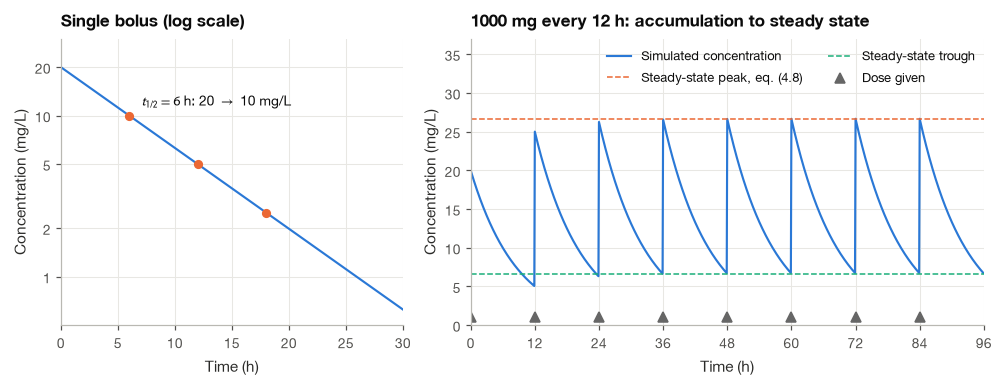

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1, 1.5]})

ax = axes[0]
ax.semilogy(t_pk, conc_single, color=C[0])
ax.set_yticks([1, 2, 5, 10, 20], labels=["1", "2", "5", "10", "20"])
ax.minorticks_off()
for h in (6, 12, 18):
    ax.plot(h, D / V * 2 ** (-h / t_half), "o", color=C[1], ms=5)
ax.annotate(r"$t_{1/2} = 6$ h: 20 $\rightarrow$ 10 mg/L", (6, 10), textcoords="offset points",
            xytext=(8, 6), fontsize=9)
ax.set(xlim=(0, 30), ylim=(0.5, 30), xlabel="Time (h)", ylabel="Concentration (mg/L)",
       title="Single bolus (log scale)")

ax = axes[1]
ax.plot(t_pk, conc_rep, color=C[0], label="Simulated concentration")
ax.axhline(peak_ss, color=C[1], ls="--", lw=1, label="Steady-state peak, eq. (4.8)")
ax.axhline(peak_ss * rho, color=C[2], ls="--", lw=1, label="Steady-state trough")
ax.plot(t_pk[dose_idx], np.full(dose_idx.size, 1.0), "^", color="0.4", ms=6, label="Dose given")
ax.set(xlim=(0, 96), ylim=(0, 37), xticks=np.arange(0, 97, 12), xlabel="Time (h)",
       ylabel="Concentration (mg/L)", title="1000 mg every 12 h: accumulation to steady state")
ax.legend(loc="upper right", ncols=2, fontsize=8.5)
plt.show()

(sec-3-1-4)=
## 3.1.4 A Feedback System in the Body: The Baroreflex

In the systems so far, information flows in one direction, from input to output. Many physiological systems instead *measure their own output and act on it*. The arterial baroreflex is the classic example. Stretch receptors in the walls of the carotid sinus and the aortic arch fire faster when arterial pressure rises. Their signals travel through the glossopharyngeal and vagus nerves to the nucleus tractus solitarius in the medulla, which adjusts the autonomic outflow to the heart and blood vessels. When pressure falls, sympathetic activity increases and vagal activity decreases: heart rate, contractility and peripheral resistance all rise, pushing the pressure back up. The output (pressure) is fed back to influence the input of the heart and vessels. This is a **feedback system**.

The value of the reflex is easiest to appreciate when it fails. On standing up, roughly half a liter of blood shifts into the veins of the legs, venous return falls, and without correction arterial pressure would drop and stay low. In a healthy person the reflex restores the pressure within seconds. When it is impaired, as in some neurological diseases or under certain medications, the pressure stays low; a sustained fall in systolic pressure of at least 20 mmHg within three minutes of standing is the clinical definition of orthostatic hypotension.

I have kept the following model deliberately minimal, because its only job is to capture the loop structure. Let $p(t)$ be the deviation of mean arterial pressure from its set point (mmHg), $d(t)$ the disturbance (the pressure change that would occur without the reflex), and $u(t)$ the correction produced by the reflex. The circulation responds to the sum of the two with a first-order lag of time constant $\tau_c$,

(eq-3-10)=
\begin{equation*}
\tau_c\,\frac{dp}{dt} = -p(t) + d(t) + u(t), \tag{3.10}
\end{equation*}

and the reflex opposes the measured deviation with a loop gain $K$ after a delay $\Delta$ that reflects the slow sympathetic pathway,

(eq-3-11)=
\begin{equation*}
u(t) = -K\,p(t - \Delta). \tag{3.11}
\end{equation*}

**Steady state.** Suppose the disturbance is a step of size $d_0$ that stays on. Once the transients have died out, $p$ is constant, so $dp/dt = 0$ and $p(t - \Delta) = p(t) = p_{\text{ss}}$. Substituting into [(3.10)](#eq-3-10) and [(3.11)](#eq-3-11),

(eq-3-12)=
\begin{equation*}
\begin{aligned}
0 &= -p_{\text{ss}} + d_0 - K\,p_{\text{ss}} \\[2pt]
p_{\text{ss}} &= \frac{d_0}{1 + K}.
\end{aligned} \tag{3.12}
\end{equation*}

Without the reflex ($K = 0$) the full disturbance appears in the output. With feedback it is divided by $1 + K$. The delay does not affect this result, but it strongly affects how the system gets there. The simulation below uses $d_0 = -20$ mmHg, $\tau_c = 4$ s and $\Delta = 3$ s; these are illustrative values chosen to show the qualitative behavior, not fitted parameters. We integrate equations [(3.10)](#eq-3-10) and [(3.11)](#eq-3-11) with small Euler steps of 10 ms (Section 2.3), which turns the continuous-time model into a discrete-time recursion very much like equation [(3.9)](#eq-3-9).

In [6]:
def baroreflex(K, d0=-20.0, tau_c=4.0, delay=3.0, t_on=5.0, T=70.0, dt=0.01):
    """Euler simulation of the minimal baroreflex loop, equations (4.10) and (4.11)."""
    n = int(round(T / dt))
    t = np.arange(n) * dt
    d = np.where(t >= t_on, d0, 0.0)
    p = np.zeros(n)
    lag = int(round(delay / dt))
    for i in range(1, n):
        u = -K * p[i - 1 - lag] if i - 1 - lag >= 0 else 0.0
        p[i] = p[i - 1] + dt / tau_c * (-p[i - 1] + d[i - 1] + u)
    return t, d, p


results = {K: baroreflex(K) for K in (0.0, 2.0, 3.0)}
for K, (t_b, d_b, p_b) in results.items():
    tail = p_b[t_b > 50]
    print(f"K = {K:.0f}: predicted p_ss = {-20 / (1 + K):6.2f} mmHg, "
          f"last 20 s range [{tail.min():6.2f}, {tail.max():6.2f}] mmHg")

K = 0: predicted p_ss = -20.00 mmHg, last 20 s range [-20.00, -20.00] mmHg
K = 2: predicted p_ss =  -6.67 mmHg, last 20 s range [ -6.85,  -6.54] mmHg
K = 3: predicted p_ss =  -5.00 mmHg, last 20 s range [-24.61,  12.81] mmHg


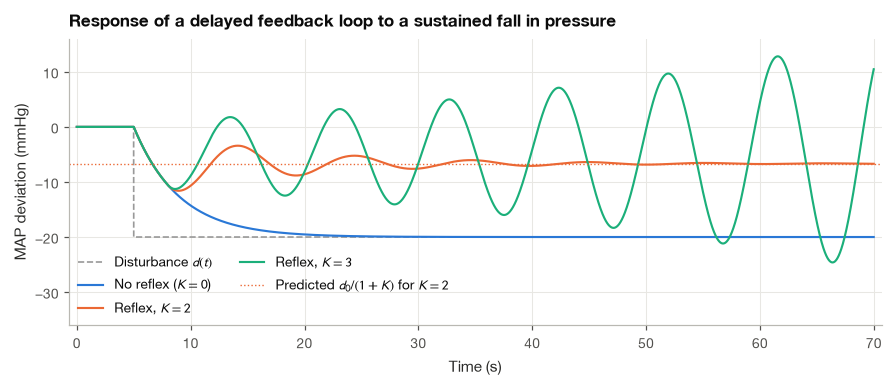

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
t_b, d_b, _ = results[0.0]
ax.plot(t_b, d_b, color="0.6", ls="--", lw=1.1, label="Disturbance $d(t)$")
labels = {0.0: "No reflex ($K = 0$)", 2.0: "Reflex, $K = 2$", 3.0: "Reflex, $K = 3$"}
for c, K in zip((C[0], C[1], C[2]), (0.0, 2.0, 3.0)):
    ax.plot(t_b, results[K][2], color=c, label=labels[K])
ax.axhline(-20 / 3, color=C[1], lw=0.9, ls=":", label=r"Predicted $d_0/(1+K)$ for $K = 2$")
ax.set(xlabel="Time (s)", ylabel="MAP deviation (mmHg)", ylim=(-36, 16),
       title="Response of a delayed feedback loop to a sustained fall in pressure")
ax.legend(loc="lower left", ncols=2)
plt.show()

The figure shows three distinct behaviors. Without the reflex the pressure settles 20 mmHg low. With $K = 2$ it settles only 6.7 mmHg low, as equation [(3.12)](#eq-3-12) predicts, but because the correction arrives three seconds late, the loop first overshoots and then rings with a period of about ten seconds. With $K = 3$ the same delay turns the ringing into an oscillation that grows: the correction now arrives so late and so strongly that it pushes the pressure past the set point each time. Feedback with delay can stabilize or destabilize, depending on the gain.

Slow oscillations of arterial pressure near 0.1 Hz, known as Mayer waves, are present in most people, and one widely discussed explanation is exactly this kind of resonance of the delayed sympathetic limb of the baroreflex. The real reflex is far richer than our model: it has several effectors with different time scales, a sigmoid rather than linear relation between pressure and nerve activity, and interactions with breathing. What the model keeps is the structure, a loop with gain and delay, and that structure is enough to explain both the benefit of feedback and its risk. We return to stability in Section 4.3.

(sec-3-1-5)=
## 3.1.5 Block Diagrams and Interconnections

Real processing chains and physiological models are built from smaller systems, and **block diagrams** show how they are connected. A box is a system, an arrow is a signal, and a circle with a $\Sigma$ adds its incoming signals (with the signs written next to the arrows). Three basic connections cover almost everything we will need. I find a feedback diagram easiest to read by putting a finger on the input and following the signal once around the loop.

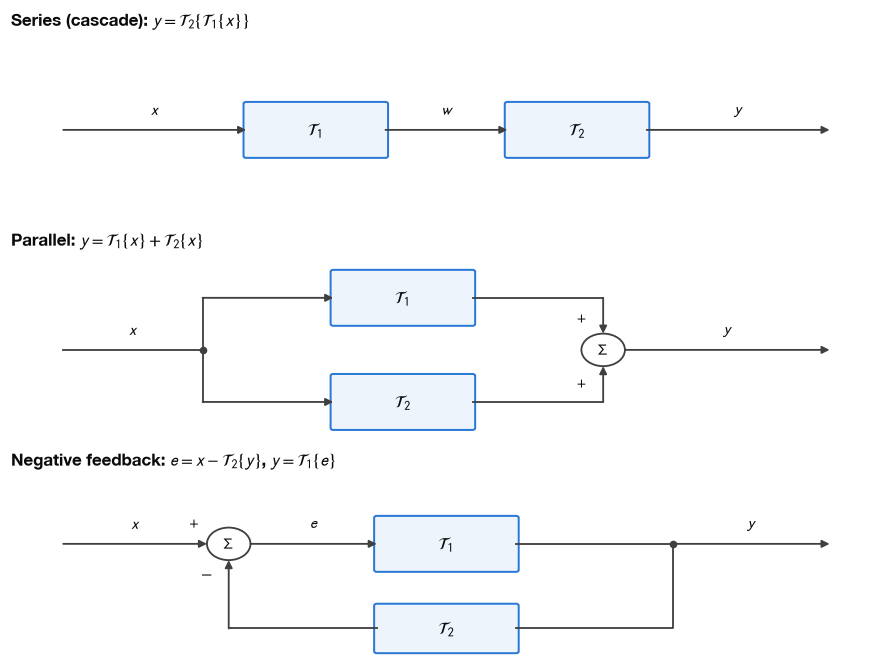

In [8]:
def block(ax, x, y, text, w=1.6, h=0.8):
    """Draw a system block centered at (x, y)."""
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.03",
                                fc="#eef4fc", ec=C[0], lw=1.3))
    ax.text(x, y, text, ha="center", va="center", fontsize=11)


def summer(ax, x, y, r=0.25):
    """Draw a summing junction centered at (x, y)."""
    ax.add_patch(Circle((x, y), r, fc="white", ec="0.25", lw=1.2))
    ax.text(x, y, r"$\Sigma$", ha="center", va="center", fontsize=10)


def arrow(ax, start, end, label=None, offset=(0, 0.18), color="0.25"):
    """Draw a signal arrow from start to end, with an optional label."""
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2,
                                                          shrinkA=0, shrinkB=0))
    if label:
        ax.text((start[0] + end[0]) / 2 + offset[0], (start[1] + end[1]) / 2 + offset[1], label,
                ha="center", va="bottom", fontsize=10)


def line(ax, pts):
    """Draw a plain connecting line through a list of points."""
    xs, ys = zip(*pts)
    ax.plot(xs, ys, color="0.25", lw=1.2)


fig, axes = plt.subplots(3, 1, figsize=(8, 6.0))
for ax in axes:
    ax.set(xlim=(0, 10), ylim=(-0.2, 2.6))
    ax.axis("off")

ax = axes[0]
arrow(ax, (0.6, 1.2), (2.7, 1.2), "$x$")
block(ax, 3.5, 1.2, r"$\mathcal{T}_1$")
arrow(ax, (4.3, 1.2), (5.7, 1.2), "$w$")
block(ax, 6.5, 1.2, r"$\mathcal{T}_2$")
arrow(ax, (7.3, 1.2), (9.4, 1.2), "$y$")
ax.set_title(r"Series (cascade): $y = \mathcal{T}_2\{\mathcal{T}_1\{x\}\}$")

ax = axes[1]
line(ax, [(0.6, 1.2), (2.2, 1.2)])
ax.plot(2.2, 1.2, "o", color="0.25", ms=4)
line(ax, [(2.2, 1.2), (2.2, 2.0)])
line(ax, [(2.2, 1.2), (2.2, 0.4)])
ax.text(1.4, 1.38, "$x$", ha="center", va="bottom", fontsize=10)
arrow(ax, (2.2, 2.0), (3.7, 2.0))
arrow(ax, (2.2, 0.4), (3.7, 0.4))
block(ax, 4.5, 2.0, r"$\mathcal{T}_1$")
block(ax, 4.5, 0.4, r"$\mathcal{T}_2$")
line(ax, [(5.3, 2.0), (6.8, 2.0)])
line(ax, [(5.3, 0.4), (6.8, 0.4)])
arrow(ax, (6.8, 2.0), (6.8, 1.45))
arrow(ax, (6.8, 0.4), (6.8, 0.95))
summer(ax, 6.8, 1.2)
ax.text(6.55, 1.62, "+", fontsize=10, ha="center")
ax.text(6.55, 0.62, "+", fontsize=10, ha="center")
arrow(ax, (7.05, 1.2), (9.4, 1.2), "$y$")
ax.set_title(r"Parallel: $y = \mathcal{T}_1\{x\} + \mathcal{T}_2\{x\}$")

ax = axes[2]
arrow(ax, (0.6, 1.6), (2.25, 1.6), "$x$")
summer(ax, 2.5, 1.6)
ax.text(2.1, 1.85, "+", fontsize=10, ha="center")
ax.text(2.25, 1.05, r"$-$", fontsize=11, ha="center")
arrow(ax, (2.75, 1.6), (4.2, 1.6), "$e$")
block(ax, 5.0, 1.6, r"$\mathcal{T}_1$")
line(ax, [(5.8, 1.6), (7.6, 1.6)])
ax.plot(7.6, 1.6, "o", color="0.25", ms=4)
arrow(ax, (7.6, 1.6), (9.4, 1.6), "$y$")
line(ax, [(7.6, 1.6), (7.6, 0.3), (5.8, 0.3)])
block(ax, 5.0, 0.3, r"$\mathcal{T}_2$", h=0.7)
line(ax, [(4.2, 0.3), (2.5, 0.3)])
arrow(ax, (2.5, 0.3), (2.5, 1.35))
ax.set_title(r"Negative feedback: $e = x - \mathcal{T}_2\{y\}$, $y = \mathcal{T}_1\{e\}$")
plt.show()

**Series (cascade).** The output of the first system is the input of the second, $y = \mathcal{T}_2\{\mathcal{T}_1\{x\}\}$. The acquisition chain of [Section 3.1](#sec-3-1) (electrode, amplifier, filter, converter) is a cascade, and so is the QRS detector we build below. In general *the order matters*: squaring and then differencing is not the same as differencing and then squaring. For the special class of linear time-invariant systems the order does not matter, a fact proved in [Section 5.4](../ch05_convolution/index.md) and checked numerically in Section 3.1.6.

**Parallel.** The same input drives two systems and their outputs are added, $y = \mathcal{T}_1\{x\} + \mathcal{T}_2\{x\}$. A filter that keeps a signal and adds back a scaled version of its derivative, used to sharpen edges, has this form.

**Feedback.** The output is passed through a second system and subtracted from the input; the difference $e$, often called the error signal, drives the first system. The baroreflex has this structure, with the circulation in the forward path and the receptors and brainstem in the feedback path.

When both blocks are simple gains, $\mathcal{T}_1\{x\} = G\,x$ and $\mathcal{T}_2\{x\} = H\,x$, the three connections reduce to single equivalent gains. A cascade gives $y = H(Gx) = GH\,x$ and a parallel connection gives $y = (G + H)\,x$. The feedback loop takes one more step, because $y$ appears on both sides:

(eq-3-13)=
\begin{equation*}
\begin{aligned}
y &= G\,e = G\,(x - H\,y) \\[2pt]
y\,(1 + GH) &= G\,x \\[2pt]
y &= \frac{G}{1 + GH}\,x.
\end{aligned} \tag{3.13}
\end{equation*}

The product $GH$ is the **loop gain**. When it is large, $G/(1 + GH) \approx 1/H$: the closed-loop behavior is set almost entirely by the feedback path, and the forward gain $G$ hardly matters. This is why amplifiers built around an operational amplifier with an enormous but poorly controlled open-loop gain still have precise, stable gains set by two resistors, and why equation [(3.12)](#eq-3-12) is the special case $G = 1$, $H = K$. The next cell checks the claim: doubling a forward gain of 100 changes the closed-loop gain by less than five percent.

In [9]:
def feedback_gain(G, H):
    """Closed-loop gain of a negative-feedback loop with static gains, equation (4.13)."""
    return G / (1 + G * H)


H = 0.1
for G in (100, 200, 1000, 1e6):
    print(f"G = {G:>9.0f}, H = {H}:  closed-loop gain = {feedback_gain(G, H):.4f}   (1/H = {1 / H:.1f})")
change = feedback_gain(200, H) / feedback_gain(100, H) - 1
print(f"Doubling G from 100 to 200 changes the closed-loop gain by {100 * change:.1f} %")

G =       100, H = 0.1:  closed-loop gain = 9.0909   (1/H = 10.0)
G =       200, H = 0.1:  closed-loop gain = 9.5238   (1/H = 10.0)
G =      1000, H = 0.1:  closed-loop gain = 9.9010   (1/H = 10.0)
G =   1000000, H = 0.1:  closed-loop gain = 9.9999   (1/H = 10.0)
Doubling G from 100 to 200 changes the closed-loop gain by 4.8 %


(sec-3-1-6)=
## 3.1.6 Discrete-Time Systems in Python on a Real ECG

A discrete-time system is, in code, simply a function that takes an array and returns an array of the same length. In this subsection we write the systems from [Section 3.1.2](#sec-3-1-2) in that form, apply each one to a real ECG from MIT-BIH record 100 {cite:p}`moody2001,goldberger2000`, and then chain three of them into the front end of a QRS detector. I have broken the work into small steps so that you can reproduce each one and change it.

### Step 1: Select an excerpt and look at its numbers

We already loaded the first 30 s of lead MLII in Section 3.1.1. Four seconds are enough to see every wave clearly, so we cut the excerpt from 10 s to 14 s and keep the annotated beats that fall inside it.

In [10]:
seg = slice(10 * fs, 14 * fs)
x = ecg[seg]
t_seg = t[seg]
r_seg = r_peaks[(r_peaks >= seg.start) & (r_peaks < seg.stop)] - seg.start

rr = np.diff(r_peaks) / fs
print(f"Excerpt: {x.size} samples ({x.size / fs:.0f} s), {r_seg.size} annotated beats")
print(f"Mean RR interval in the first 30 s: {rr.mean():.3f} s  ->  heart rate {60 / rr.mean():.0f} bpm")
print(f"Mean of the excerpt (baseline offset): {x.mean():.3f} mV, R-peak amplitudes: {np.round(x[r_seg], 2)} mV")

Excerpt: 1440 samples (4 s), 4 annotated beats
Mean RR interval in the first 30 s: 0.811 s  ->  heart rate 74 bpm
Mean of the excerpt (baseline offset): -0.321 mV, R-peak amplitudes: [0.88 0.86 0.8  0.82] mV


The heart rate is about 75 beats per minute and, importantly for what follows, the whole excerpt sits on a baseline of about $-0.3$ mV rather than at zero.

### Step 2: Write each system as a function

Every system with memory needs input samples from before the start of the array. We adopt the convention of **initial rest**: the input is taken to be zero before the first sample. For an excerpt cut from the middle of a recording this is not true, so the first few output samples form a start-up transient, which we will see rather than hide.

In [11]:
def amplifier(x, gain):
    """Static gain, y[n] = G x[n]."""
    return gain * x


def moving_average(x, M):
    """Causal M-point moving average, equation (4.3), assuming x[n] = 0 for n < 0."""
    c = np.cumsum(np.concatenate([np.zeros(M), x]))
    return (c[M:] - c[:-M]) / M


def first_difference(x):
    """First difference y[n] = x[n] - x[n-1], equation (4.4), assuming x[-1] = 0."""
    return x - np.concatenate([[0.0], x[:-1]])


def squarer(x):
    """Memoryless squarer, y[n] = x[n]^2."""
    return x**2


def rectifier(x):
    """Full-wave rectifier, y[n] = |x[n]|."""
    return np.abs(x)


ref = np.convolve(x, np.ones(9) / 9)[: x.size]
print(f"moving_average vs np.convolve, max |difference|: {np.max(np.abs(moving_average(x, 9) - ref)):.1e} mV")
print(f"amplifier(x, 1000) at the first R peak: {amplifier(x, 1000)[r_seg[0]]:.0f} mV")

moving_average vs np.convolve, max |difference|: 2.1e-14 mV
amplifier(x, 1000) at the first R peak: 885 mV


The moving average uses a running (cumulative) sum, so its cost does not grow with $M$; it agrees with NumPy's convolution to rounding error. The amplifier needs no further comment: a gain of 1000 turns the 0.88 mV R peak into 880 mV.

### Step 3: Apply each system and compare the outputs

In [12]:
outputs = {
    "moving average, M = 9": (moving_average(x, 9), "mV"),
    "first difference": (first_difference(x), "mV"),
    "squarer": (squarer(x), "mV²"),
    "rectifier": (rectifier(x), "mV"),
}
d = outputs["first difference"][0]
print(f"First difference: n = 0 sample {d[0]:.3f} mV, largest |value| afterwards {np.max(np.abs(d[1:])):.3f} mV")

First difference: n = 0 sample -0.390 mV, largest |value| afterwards 0.410 mV


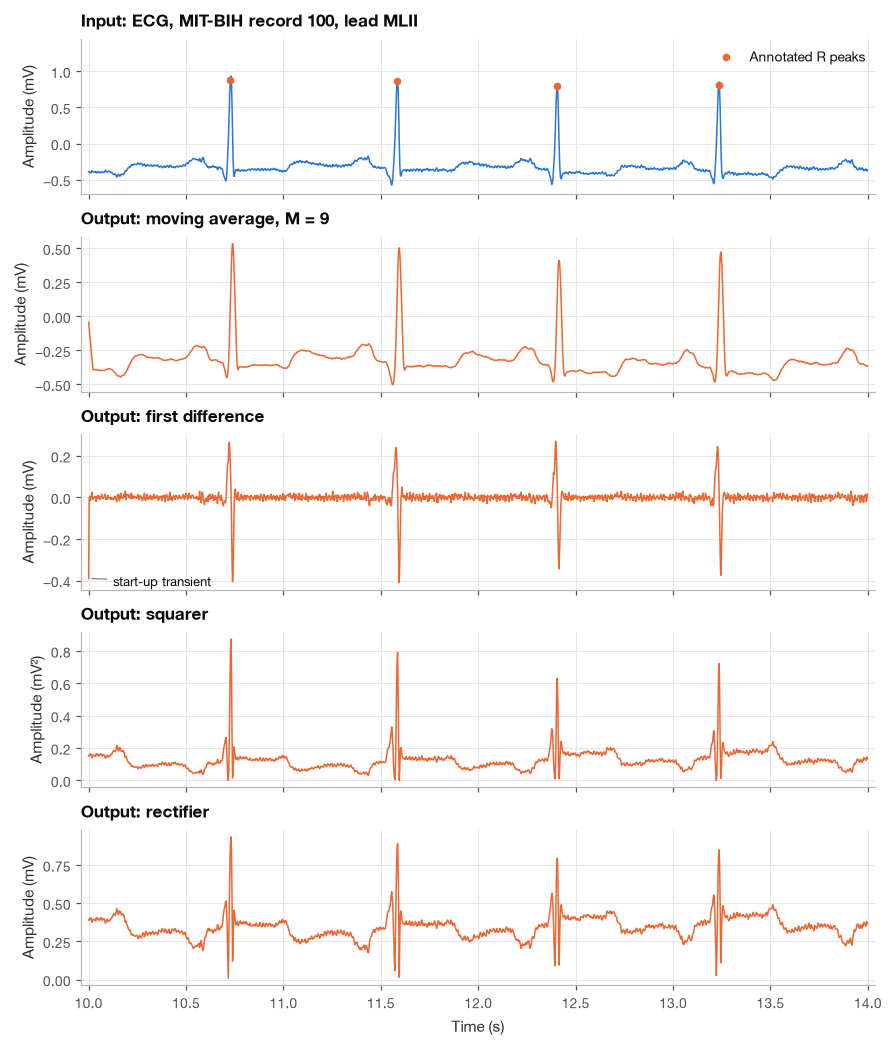

In [13]:
fig, axes = plt.subplots(5, 1, figsize=(8, 9.4), sharex=True)
axes[0].plot(t_seg, x, color=C[0], lw=1)
axes[0].plot(t_seg[r_seg], x[r_seg], "o", color=C[1], ms=4, label="Annotated R peaks")
axes[0].set(ylabel="Amplitude (mV)", ylim=(-0.7, 1.45), title="Input: ECG, MIT-BIH record 100, lead MLII")
axes[0].legend(loc="upper right")
for ax, (name, (y, unit)) in zip(axes[1:], outputs.items()):
    ax.plot(t_seg, y, color=C[1], lw=1)
    ax.set(ylabel=f"Amplitude ({unit})", title=f"Output: {name}")
axes[2].annotate("start-up transient", (t_seg[0], d[0]), textcoords="offset points",
                 xytext=(16, -2), fontsize=8.5, va="center",
                 arrowprops=dict(arrowstyle="-", color="0.5", lw=0.8))
axes[-1].set_xlabel("Time (s)")
plt.show()

Each output tells us something about the system that produced it. The moving average leaves the waves in place but lowers and rounds the sharp QRS peak, because averaging over 25 ms smears fast changes. The first difference removes the baseline completely (a constant input has zero difference) and turns each QRS complex into a sharp biphasic deflection, while the P and T waves almost vanish. Its first sample, $-0.39$ mV, is the start-up transient: under initial rest the system sees the input jump from 0 to the baseline at $n = 0$, a step as large as the QRS slopes themselves.

The squarer and the rectifier are more subtle. Because the excerpt sits on a negative baseline, the long isoelectric stretches between beats become *positive* plateaus in both outputs, and the S wave produces a peak almost as tall as the R wave. Neither system lets an additive offset pass through unchanged: an offset added to the input changes the output by an amount that depends on the signal itself. This is our first concrete sign of nonlinearity, the topic of {ref}`Section 3.2 <sec-3-2>`, and it is the reason a QRS detector squares the signal only after the baseline has been removed.

### Step 4: Chain three systems into a QRS-detector front end

Connecting three of these systems in series gives the core of the classic Pan–Tompkins QRS detector {cite:p}`pan1985`. The first difference emphasizes steep slopes, the squarer makes all deflections positive and accentuates the largest ones, and a moving average over 150 ms (54 samples at 360 Hz) merges the several peaks of each squared QRS into a single bump. The full algorithm, with its band-pass filter and adaptive thresholds, is the subject of Section 19.1. Because the first difference removes the baseline before the squarer sees the signal, the problem we noticed in Step 3 disappears.

In [14]:
M_int = int(round(0.150 * fs))
detector_full = moving_average(squarer(first_difference(ecg)), M_int)    # whole 30 s
detector_output = detector_full[seg]

delays_ms = []
for r in r_peaks:
    if r - int(0.1 * fs) < 0 or r + int(0.3 * fs) > ecg.size:
        continue
    n = np.arange(r - int(0.1 * fs), r + int(0.3 * fs))
    w = detector_full[n]
    delays_ms.append(1000 * (np.sum(n * w) / np.sum(w) - r) / fs)    # centroid of each bump
delays_ms = np.array(delays_ms)
print(f"Integration window: {M_int} samples = {1000 * M_int / fs:.0f} ms")
print(f"Centroid delay after the R peak over {delays_ms.size} beats: "
      f"{delays_ms.mean():.1f} ms (SD {delays_ms.std():.1f} ms)")
print(f"(M - 1)/2 samples = {(M_int - 1) / 2:.1f} samples = {1000 * (M_int - 1) / 2 / fs:.1f} ms")

Integration window: 54 samples = 150 ms
Centroid delay after the R peak over 37 beats: 76.5 ms (SD 1.3 ms)
(M - 1)/2 samples = 26.5 samples = 73.6 ms


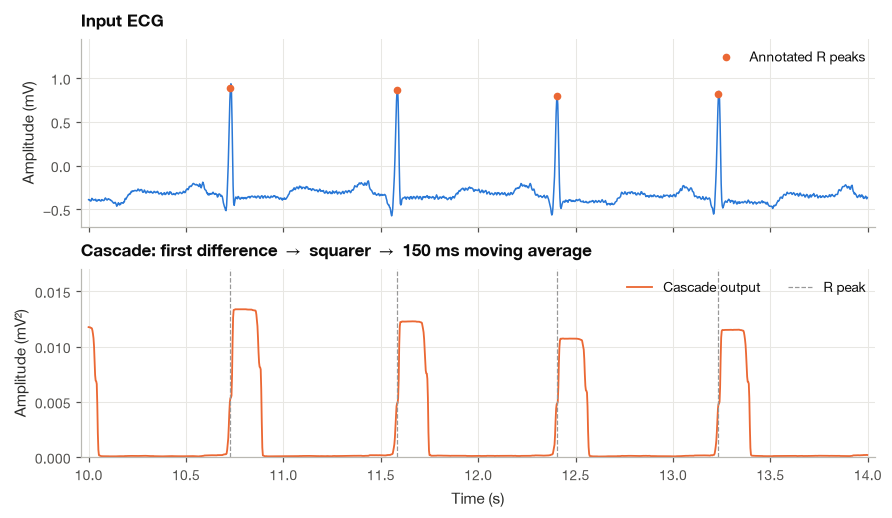

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
axes[0].plot(t_seg, x, color=C[0], lw=1)
axes[0].plot(t_seg[r_seg], x[r_seg], "o", color=C[1], ms=4, label="Annotated R peaks")
axes[0].set(ylabel="Amplitude (mV)", ylim=(-0.7, 1.45), title="Input ECG")
axes[0].legend(loc="upper right")
axes[1].plot(t_seg, detector_output, color=C[1], lw=1.2, label="Cascade output")
for k, r in enumerate(r_seg):
    axes[1].axvline(t_seg[r], color="0.6", lw=0.8, ls="--", label="R peak" if k == 0 else None)
axes[1].set(xlabel="Time (s)", ylabel="Amplitude (mV²)", ylim=(0, 0.017),
            title=r"Cascade: first difference $\rightarrow$ squarer $\rightarrow$ 150 ms moving average")
axes[1].legend(loc="upper right", ncols=2)
plt.show()

The cascade turns each heartbeat into one positive, flat-topped pulse that a simple threshold could detect. Because we computed it over the whole 30 s, the start-up transient has gone from this excerpt. The pulses are flat because the squared slope of a QRS lasts only about 20 ms, much less than the 150 ms window, so for most of the window the average contains the whole QRS. They are also late. The centroid of each pulse lags the R peak by about 76 ms, and almost all of that comes from the moving average: a causal $M$-point average can only look at the past, so a short event at sample $n_0$ produces an output spread over samples $n_0$ to $n_0 + M - 1$, centered $(M - 1)/2 = 26.5$ samples (74 ms) later. The remaining 2 to 3 ms reflect the fact that the steepest slope of this QRS is on its downstroke, just after the R peak. The delay is a direct consequence of causality, a property we define in Section 4.3.

### Step 5: Check whether the order of a cascade matters

Finally, we test the claim made in Section 3.1.5. The moving average and the first difference are both linear and time-invariant, so they should commute; the squarer is not, so swapping it with the first difference should change the result.

In [16]:
lti_a = moving_average(first_difference(x), 9)
lti_b = first_difference(moving_average(x, 9))
nl_a = squarer(first_difference(x))
nl_b = first_difference(squarer(x))

print(f"MA then difference vs difference then MA:          max |diff| = {np.max(np.abs(lti_a - lti_b)):.1e} mV")
print(f"square then difference vs difference then square:  max |diff| = {np.max(np.abs(nl_a - nl_b)):.3f} mV²")
print(f"largest value of the squared difference itself:                   {np.max(nl_a):.3f} mV²")

MA then difference vs difference then MA:          max |diff| = 6.1e-15 mV
square then difference vs difference then square:  max |diff| = 0.518 mV²
largest value of the squared difference itself:                   0.168 mV²


The two LTI systems commute to within rounding error, while swapping the squarer with the difference changes the output by about half a mV², more than the whole height of the squared-difference output. Keeping track of which systems belong to the LTI class is therefore not pedantry. In my experience it is the first thing to check before rearranging a processing chain, because it tells us which rearrangements are safe.

## Summary

A system is a rule $y = \mathcal{T}\{x\}$ that maps a whole input signal to a whole output signal. Continuous-time systems such as RC networks are often described by differential equations, discrete-time systems such as moving averages and first differences by explicit formulas or recursions, and the same mathematics can describe very different objects: equation [(3.5)](#eq-3-5) for a drug cleared by the body is the RC equation [(3.2)](#eq-3-2) in another guise. Solving it gave the exponential decay $C(t) = (D/V)e^{-kt}$, the half-life $\ln 2/k$, and, by adding shifted copies of that response, the steady-state accumulation factor $1/(1 - e^{-k\tau})$. Feedback, as in the baroreflex, divides a disturbance by $1 + K$ and makes the closed-loop gain $G/(1 + GH)$ insensitive to the forward path, but combined with delay it can also cause ringing and instability.

Writing systems as Python functions and applying them to a real ECG showed that simple building blocks, connected in series, already form the front end of a QRS detector, and that the order of the blocks matters unless they are all linear and time-invariant. The next two sections turn the informal questions of this section into precise definitions. [Section 3.2](02_linearity.ipynb) defines linearity and superposition, and [Section 4.3](index.md) defines time invariance, causality, memory, invertibility and stability. Systems that are both linear and time-invariant are completely characterized by their impulse response, which is the starting point of [Chapter 4](../ch05_convolution/index.md).

## Exercises

1. For each of the following, identify the input and output signals, say whether the system is continuous-time, discrete-time or a hybrid, and write it in operator notation: (a) a thermometer that displays the body temperature once per second; (b) a pulse oximeter that converts red and infrared light intensities into an $\text{SpO}_2$ value every second; (c) the left ventricle, which converts a filling volume into a stroke volume.
2. Redraw the feedback diagram of [Section 3.1.5](#sec-3-1-5) with a *positive* sign at the feedback input of the summer. Derive the closed-loop gain for static gains $G$ and $H$, and describe what happens as $GH$ approaches 1.
3. For the one-compartment model with $V = 50$ L, $t_{1/2} = 6$ h and $D = 1000$ mg every 12 h, derive a closed-form expression for the trough concentration just before the $(n+1)$-th dose. Then find the *loading dose* $D_L$ that, given once at $t = 0$ followed by the usual maintenance doses, reaches the steady-state peak immediately. Check your answer by simulation with `one_compartment`.
4. Implement a three-point *centered* moving average $y[n] = \tfrac{1}{3}(x[n-1] + x[n] + x[n+1])$ and apply it to the same ECG excerpt. Compare the timing of the R peaks in its output with that of the causal three-point average. Which of the two could run on a bedside monitor in real time?
5. Load `emg_healthy` from `../data/emgdb/` and compute an envelope by cascading the rectifier with a 50 ms moving average. Repeat with the order reversed. Plot both results over one second and explain the difference.
6. In the baroreflex model, keep $\tau_c = 4$ s and $\Delta = 3$ s and find numerically the smallest gain $K$ for which the oscillation no longer decays. Repeat for $\Delta = 1.5$ s. How does the largest safe gain depend on the delay?

## Further Reading

The input-output view of systems and block-diagram algebra are introduced in Chapter 1 of {cite:t}`oppenheim1997` and in the first chapter of {cite:t}`lathi2018`. {cite:t}`bruce2001` and {cite:t}`semmlow2014` develop the systems viewpoint specifically for biomedical signals. {cite:t}`khoo2018` treats physiological feedback loops, including the baroreflex and compartmental models, as engineering control systems, and {cite:t}`webster2010` covers electrodes and amplifiers in the acquisition chain.